<a href="https://colab.research.google.com/github/synatkeamsk/rbc-morphology/blob/main/notebooks/colab_train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!nvidia-smi

Wed Nov 11 04:16:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Clone your repo and enter the folder
!git clone https://github.com/synatkeamsk/rbc-morphology.git
%cd rbc-morphology

# Install remaining libraries
!pip install -q timm albumentations opencv-python-headless onnx onnxruntime

Cloning into 'rbc-morphology'...
remote: Enumerating objects: 78, done.
remote: Counting objects: 100% (78/78), done.
remote: Compressing objects: 100% (61/61), done.
remote: Total 78 (delta 26), reused 55 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (78/78), 438.48 KiB | 1.78 MiB/s, done.
Resolving deltas: 100% (26/26), done.
/content/rbc-morphology


In [3]:
!python src/model.py

In [4]:
import os
import cv2
import numpy as np
import pandas as pd

# Create dummy sample RBC patches
os.makedirs("data/raw/synthetic", exist_ok=True)
os.makedirs("data/splits", exist_ok=True)

records = []
classes = ["normal", "drepanocyte", "dacrocyte", "schistocyte", "echinocyte", "elliptocyte", "spherocyte", "codocyte"]

for i in range(160):
    label_idx = i % len(classes)
    cls_name = classes[label_idx]

    # Create a 224x224 RGB image (simulating a stained RBC crop)
    img = np.random.randint(180, 240, (224, 224, 3), dtype=np.uint8)
    cv2.circle(img, (112, 112), 60, (120, 50, 160), -1) # Cell body
    cv2.circle(img, (112, 112), 25, (220, 200, 220), -1) # Central pallor

    path = f"data/raw/synthetic/cell_{i}_{cls_name}.png"
    cv2.imwrite(path, img)
    records.append({"image_path": path, "label": label_idx})

df = pd.DataFrame(records)
# Split 80% train, 20% val
train_df = df.sample(frac=0.8, random_state=42)
val_df = df.drop(train_df.index)

train_df.to_csv("data/splits/train.csv", index=False)
val_df.to_csv("data/splits/val.csv", index=False)

print(f"Created {len(train_df)} train samples and {len(val_df)} validation samples.")

Created 128 train samples and 32 validation samples.


In [5]:
%%bash
# Add project root to sys.path in src/train.py
python3 -c "
import sys
content = open('src/train.py').read()
if 'sys.path.append' not in content:
    header = 'import sys\nfrom pathlib import Path\nsys.path.append(str(Path(__file__).resolve().parents[1]))\n\n'
    open('src/train.py', 'w').write(header + content)
"

# Add project root to sys.path in src/infer.py
python3 -c "
import sys
content = open('src/infer.py').read()
if 'sys.path.append' not in content:
    header = 'import sys\nfrom pathlib import Path\nsys.path.append(str(Path(__file__).resolve().parents[1]))\n\n'
    open('src/infer.py', 'w').write(header + content)
"

In [6]:
import re
from pathlib import Path

# 1. Update backbone name to 'convnext_nano' in all files
for file in ["src/config.py", "src/model.py", "src/train.py", "src/infer.py"]:
    p = Path(file)
    if p.exists():
        content = p.read_text().replace("convnext_nano.in12k_ft_in1k_224", "convnext_nano")
        p.write_text(content)

# 2. Update default workers from 4 to 2 (optimized for Colab's 2 CPU cores)
for file, old_val, new_val in [
    ("src/config.py", "num_workers: int = 4", "num_workers: int = 2"),
    ("src/train.py", "default=4", "default=2"),
]:
    p = Path(file)
    if p.exists():
        p.write_text(p.read_text().replace(old_val, new_val))

# 3. Replace deprecated ShiftScaleRotate with modern Affine in src/data.py
p = Path("src/data.py")
if p.exists():
    content = p.read_text()
    content = re.sub(
        r"A\.ShiftScaleRotate\([^)]*p=0\.7\s*\)",
        "A.Affine(scale=(0.9, 1.1), translate_percent=(-0.06, 0.06), rotate=(-180, 180), border_mode=cv2.BORDER_REFLECT, p=0.7)",
        content,
        flags=re.DOTALL
    )
    p.write_text(content)

print("All fixes applied cleanly!")

All fixes applied cleanly!


In [7]:
!python -m src.train \
    --train_csv data/splits/train.csv \
    --val_csv data/splits/val.csv \
    --num_classes 8 \
    --backbone convnext_nano \
    --epochs 5 \
    --batch_size 16 \
    --num_workers 2 \
    --device cuda


model.safetensors: downloading bytes:  95% 59.5M/62.4M [00:01<00:00, 89.1MB/s, 4.40MB/s  ]
model.safetensors: downloading bytes: 100% 59.5M/59.5M [00:01<00:00, 45.6MB/s, 5.72MB/s  ]
model.safetensors: reconstructing file: 100% 62.4M/62.4M [00:01<00:00, 47.9MB/s, 6.02MB/s  ]
/content/rbc-morphology/src/train.py:109: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
Starting SmearScope training loop...
Training:   0% 0/8 [00:00<?, ?it/s]/content/rbc-morphology/src/train.py:46: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Validating:   0% 0/2 [00:00<?, ?it/s]/content/rbc-morphology/src/train.py:71: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch [01/05] Train Loss: 0.0208 | Train Acc: 0.172 | Va

In [8]:
!pip install -q onnxscript

In [9]:
!python -m src.infer \
    --export \
    --checkpoint checkpoints/best_smearscope.pt \
    --onnx_path checkpoints/best_smearscope.onnx \
    --num_classes 8

Loading checkpoint: checkpoints/best_smearscope.pt
Exporting ONNX: checkpoints/best_smearscope.onnx
/content/rbc-morphology/src/infer.py:102: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
[torch.onnx] Obtain model graph for `SmearScopeClassifier([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `SmearScopeClassifier([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
[*] ONNX model successfully verified!


In [10]:
from src.infer import SmearPredictor

# Target classes
classes = ["normal", "drepanocyte", "dacrocyte", "schistocyte", "echinocyte", "elliptocyte", "spherocyte", "codocyte"]

# Initialize ONNX inference engine
predictor = SmearPredictor(
    model_path="checkpoints/best_smearscope.onnx",
    classes=classes,
    backend="onnx"
)

# Test on one of synthetic RBC images
sample_image = "data/raw/synthetic/cell_0_normal.png"
result = predictor.predict(sample_image)

print(f"Predicted Class: {result['prediction']}")
print(f"Confidence:      {result['confidence'] * 100:.2f}%\n")
print("Class Probabilities:")
for cls, prob in result["probabilities"].items():
    print(f"  - {cls:<12}: {prob * 100:6.2f}%")

Predicted Class: dacrocyte
Confidence:      19.63%

Class Probabilities:
  - normal      :  11.66%
  - drepanocyte :  19.34%
  - dacrocyte   :  19.63%
  - schistocyte :   6.54%
  - echinocyte  :  12.17%
  - elliptocyte :   8.21%
  - spherocyte  :  16.07%
  - codocyte    :   6.38%


In [11]:
# Clean previous runs, clone fresh, and enter directory
!rm -rf rbc-morphology
!git clone https://github.com/synatkeamsk/rbc-morphology.git
%cd rbc-morphology

# Verify NVIDIA T4 GPU is assigned
!nvidia-smi

Cloning into 'rbc-morphology'...
remote: Enumerating objects: 82, done.
remote: Counting objects: 100% (82/82), done.
remote: Compressing objects: 100% (65/65), done.
remote: Total 82 (delta 28), reused 55 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (82/82), 440.04 KiB | 1.76 MiB/s, done.
Resolving deltas: 100% (28/28), done.
/content/rbc-morphology/rbc-morphology
Wed Nov 11 04:18:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=================================

In [12]:
!pip install -q timm albumentations opencv-python-headless onnx onnxruntime

In [13]:
# 1. Download raw smears
!mkdir -p data/raw
!git clone https://github.com/Chula-PIC-Lab/Chula-RBC-12-Dataset.git data/raw/chula_rbc_12

# 2. Extract single-cell patches and generate train/val splits
!python src/prepare_chula_rbc.py

Cloning into 'data/raw/chula_rbc_12'...
remote: Enumerating objects: 1848, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 1848 (delta 2), reused 1 (delta 1), pack-reused 1844 (from 1)
Receiving objects: 100% (1848/1848), 192.95 MiB | 26.86 MiB/s, done.
Resolving deltas: 100% (240/240), done.
Found 738 full blood smear images in data/raw/chula_rbc_12/Dataset...
Cropping single RBCs: 100% 738/738 [00:15<00:00, 47.84it/s]

Successfully extracted 21922 single RBC crops!

Class distribution:
class_name
normal         6330
spherocyte     3449
target_cell    2753
ovalocyte      2140
stomatocyte    1996
hypochromia    1063
elliptocyte    1052
schistocyte     897
burr_cell       785
macrocyte       689
microcyte       461
teardrop        307
Name: count, dtype: int64

[*] Class mapping saved to: data/splits/class_mapping.json
[*] Training split saved (17537 cells): data/splits/train.csv
[*] Validation split saved (4385 cells): data

In [16]:
!python -m src.train \
    --train_csv data/splits/train.csv \
    --val_csv data/splits/val.csv \
    --num_classes 12 \
    --backbone convnext_nano \
    --epochs 25 \
    --batch_size 32 \
    --num_workers 2 \
    --lr 3e-4 \
    --device cuda

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/content/rbc-morphology/rbc-morphology/src/train.py:105: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
Starting SmearScope training loop...
Training:   0% 0/548 [00:00<?, ?it/s]/content/rbc-morphology/rbc-morphology/src/train.py:42: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Validating:   0% 0/138 [00:00<?, ?it/s]/content/rbc-morphology/rbc-morphology/src/train.py:67: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch [01/25] Train Loss: 0.0043 | Train Acc: 0.080 | Va

In [18]:

#Step 1: Export to ONNX for Production
#Convert trained PyTorch checkpoint (checkpoints/best_smearscope.pt) into an optimized ONNX format. This makes inference up to 3–5× faster and allows the model to run without needing a heavy PyTorch GPU environment.

!python -m src.infer \
    --export \
    --checkpoint checkpoints/best_smearscope.pt \
    --onnx_path checkpoints/best_smearscope.onnx \
    --num_classes 12

Loading checkpoint: checkpoints/best_smearscope.pt
Exporting ONNX: checkpoints/best_smearscope.onnx
/content/rbc-morphology/rbc-morphology/src/infer.py:98: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
[torch.onnx] Obtain model graph for `SmearScopeClassifier([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `SmearScopeClassifier([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
[*] ONNX model successfully verified!


In [19]:
# Step 2: Download the Trained Model
from google.colab import files

# 1. Download your trained PyTorch weights
files.download("checkpoints/best_smearscope.pt")

# 2. Download the fast ONNX model
files.download("checkpoints/best_smearscope.onnx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Loading checkpoint from checkpoints/best_smearscope.pt...
Running validation inference...


Evaluating: 100%|██████████| 138/138 [00:19<00:00,  7.17it/s]


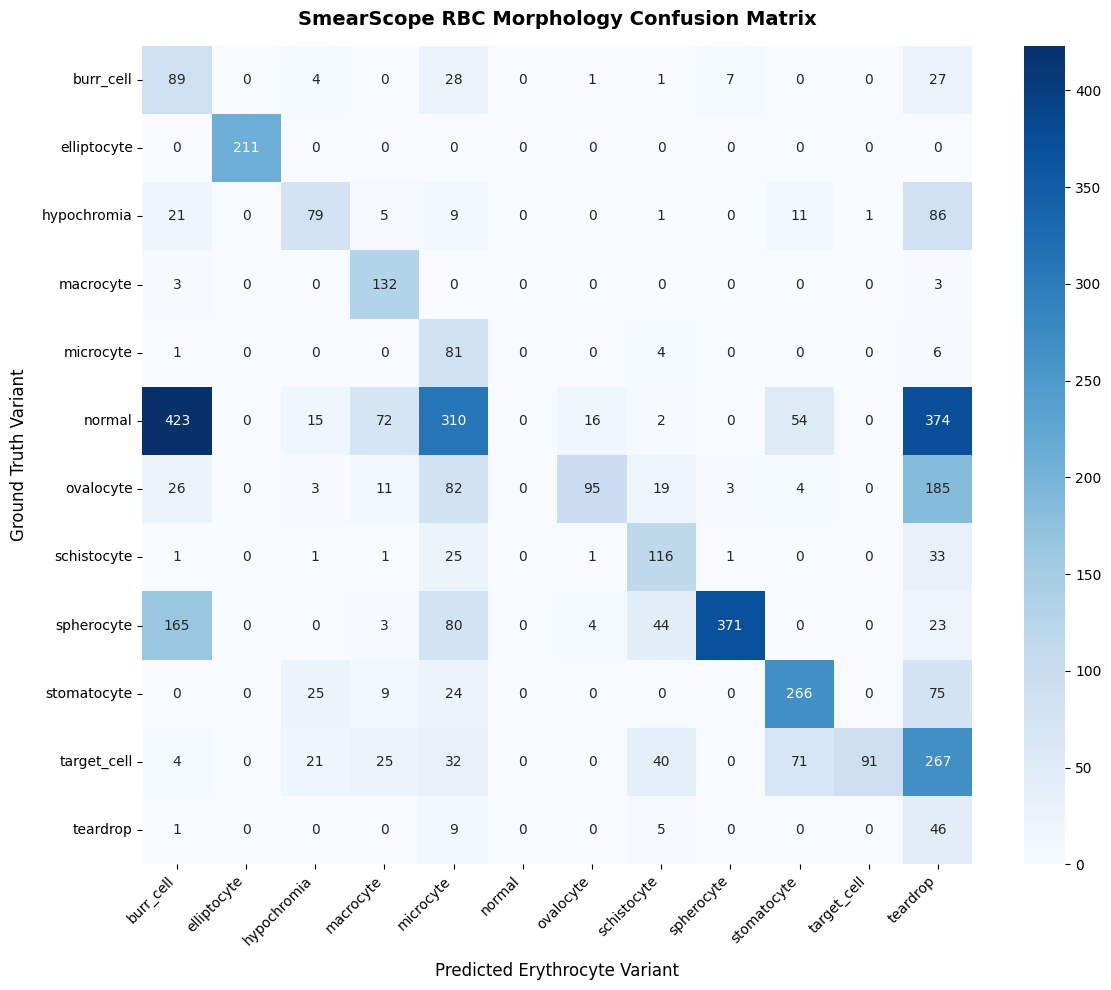


--- Validation Classification Report ---
              precision    recall  f1-score   support

   burr_cell     0.1213    0.5669    0.1998       157
 elliptocyte     1.0000    1.0000    1.0000       211
 hypochromia     0.5338    0.3709    0.4377       213
   macrocyte     0.5116    0.9565    0.6667       138
   microcyte     0.1191    0.8804    0.2098        92
      normal     0.0000    0.0000    0.0000      1266
   ovalocyte     0.8120    0.2220    0.3486       428
 schistocyte     0.5000    0.6480    0.5645       179
  spherocyte     0.9712    0.5377    0.6922       690
 stomatocyte     0.6552    0.6667    0.6609       399
 target_cell     0.9891    0.1652    0.2830       551
    teardrop     0.0409    0.7541    0.0776        61

    accuracy                         0.3596      4385
   macro avg     0.5212    0.5640    0.4284      4385
weighted avg     0.5339    0.3596    0.3647      4385



In [22]:
#Step 3: Generate the Confusion Matrix
# To assess the model's clinical diagnostic capability (e.g., Is the model successfully detecting rare schistocytes, or is it confusing them with normal cells?), generate a 12×12 Confusion Matrix heatmap:

import os
import json
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from torch.utils.data import DataLoader
from tqdm import tqdm

from src.data import RBCDataset, get_transforms
from src.model import get_model

# 1. Device and paths
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint_path = "checkpoints/best_smearscope.pt"
val_csv = "data/splits/val.csv"
mapping_path = "data/splits/class_mapping.json"

# 2. Load class names in exact numerical order
with open(mapping_path) as f:
    class_map = json.load(f)
class_names = [k for k, v in sorted(class_map.items(), key=lambda item: item[1])]
num_classes = len(class_names)

# 3. Load trained ConvNeXt weights
print(f"Loading checkpoint from {checkpoint_path}...")
model = get_model(num_classes=num_classes, backbone_name="convnext_nano", pretrained=False, device=device)
checkpoint = torch.load(checkpoint_path, map_location=device)
state_dict = checkpoint.get("model_state_dict", checkpoint)
model.load_state_dict(state_dict)
model.eval()

# 4. Prepare Validation DataLoader
val_df = pd.read_csv(val_csv)
val_dataset = RBCDataset(val_df, transform=get_transforms(img_size=224, is_train=False))
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

# 5. Run inference across the validation dataset
all_preds = []
all_targets = []

print("Running validation inference...")
with torch.no_grad():
    for images, targets in tqdm(val_loader, desc="Evaluating"):
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(targets.numpy())

# 6. Compute Confusion Matrix
cm = confusion_matrix(all_targets, all_preds)

# 7. Plot Heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True
)
plt.title("SmearScope RBC Morphology Confusion Matrix", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Predicted Erythrocyte Variant", fontsize=12, labelpad=10)
plt.ylabel("Ground Truth Variant", fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()

# Save the plot for your README
os.makedirs("docs/assets", exist_ok=True)
plt.savefig("docs/assets/confusion_matrix.png", dpi=300)
plt.show()

# 8. Print full classification metrics
print("\n--- Validation Classification Report ---")
print(classification_report(all_targets, all_preds, target_names=class_names, digits=4, zero_division=0))

In [23]:
#  Download the baseline confusion matrix image
files.download("docs/assets/confusion_matrix.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
#Add import numpy as np to src/train.py
with open("src/train.py", "r") as f:
    content = f.read()

# Add import numpy as np at the top if missing
if "import numpy as np" not in content:
    content = "import numpy as np\n" + content

with open("src/train.py", "w") as f:
    f.write(content)

print("Added 'import numpy as np' to src/train.py successfully!")

Added 'import numpy as np' to src/train.py successfully!


In [29]:
#second model training
!python -m src.train \
    --train_csv data/splits/train.csv \
    --val_csv data/splits/val.csv \
    --num_classes 12 \
    --backbone convnext_nano \
    --epochs 25 \
    --batch_size 32 \
    --num_workers 2 \
    --lr 3e-4 \
    --device cuda

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/content/rbc-morphology/rbc-morphology/src/train.py:106: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
Starting SmearScope training loop...
Training:   0% 0/548 [00:00<?, ?it/s]/content/rbc-morphology/rbc-morphology/src/train.py:43: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Validating:   0% 0/138 [00:00<?, ?it/s]/content/rbc-morphology/rbc-morphology/src/train.py:68: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch [01/25] Train Loss: 0.0036 | Train Acc: 0.180 | Va

Running validation evaluation...


Evaluating: 100%|██████████| 138/138 [00:14<00:00,  9.56it/s]


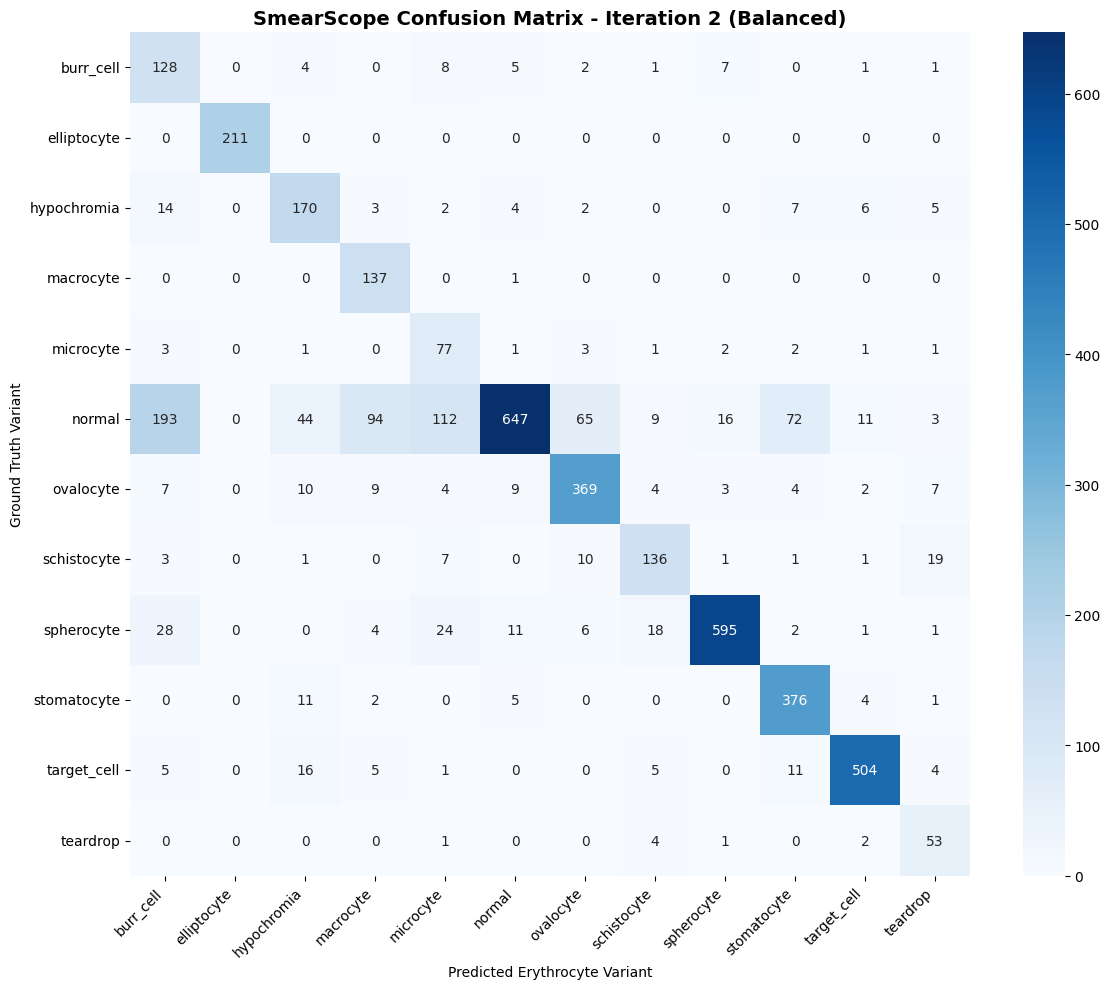


--- Validation Classification Report (Iteration 2) ---
              precision    recall  f1-score   support

   burr_cell     0.3360    0.8153    0.4758       157
 elliptocyte     1.0000    1.0000    1.0000       211
 hypochromia     0.6615    0.7981    0.7234       213
   macrocyte     0.5394    0.9928    0.6990       138
   microcyte     0.3263    0.8370    0.4695        92
      normal     0.9473    0.5111    0.6639      1266
   ovalocyte     0.8074    0.8621    0.8339       428
 schistocyte     0.7640    0.7598    0.7619       179
  spherocyte     0.9520    0.8623    0.9049       690
 stomatocyte     0.7916    0.9424    0.8604       399
 target_cell     0.9456    0.9147    0.9299       551
    teardrop     0.5579    0.8689    0.6795        61

    accuracy                         0.7761      4385
   macro avg     0.7191    0.8470    0.7502      4385
weighted avg     0.8480    0.7761    0.7833      4385



In [30]:
# Confusion matrix
import os
import json
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from torch.utils.data import DataLoader
from tqdm import tqdm

from src.data import RBCDataset, get_transforms
from src.model import get_model

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint_path = "checkpoints/best_smearscope.pt"
val_csv = "data/splits/val.csv"
mapping_path = "data/splits/class_mapping.json"

# Load class names
with open(mapping_path) as f:
    class_map = json.load(f)
class_names = [k for k, v in sorted(class_map.items(), key=lambda item: item[1])]
num_classes = len(class_names)

# Load model
model = get_model(num_classes=num_classes, backbone_name="convnext_nano", pretrained=False, device=device)
checkpoint = torch.load(checkpoint_path, map_location=device)
state_dict = checkpoint.get("model_state_dict", checkpoint)
model.load_state_dict(state_dict)
model.eval()

# DataLoader
val_df = pd.read_csv(val_csv)
val_dataset = RBCDataset(val_df, transform=get_transforms(img_size=224, is_train=False))
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

all_preds = []
all_targets = []

print("Running validation evaluation...")
with torch.no_grad():
    for images, targets in tqdm(val_loader, desc="Evaluating"):
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(targets.numpy())

# Plot Heatmap
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("SmearScope Confusion Matrix - Iteration 2 (Balanced)", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Erythrocyte Variant")
plt.ylabel("Ground Truth Variant")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("docs/assets/confusion_matrix_balanced.png", dpi=300)
plt.show()

# Print metrics
print("\n--- Validation Classification Report (Iteration 2) ---")
print(classification_report(all_targets, all_preds, target_names=class_names, digits=4, zero_division=0))

In [32]:
!python -m src.infer \
    --export \
    --checkpoint checkpoints/best_smearscope.pt \
    --onnx_path checkpoints/best_smearscope.onnx \
    --num_classes 12

Loading checkpoint: checkpoints/best_smearscope.pt
Exporting ONNX: checkpoints/best_smearscope.onnx
/content/rbc-morphology/rbc-morphology/src/infer.py:98: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
[torch.onnx] Obtain model graph for `SmearScopeClassifier([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `SmearScopeClassifier([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
[*] ONNX model successfully verified!
